In [2]:
import copy
import random
from typing import Callable, Dict, List, Tuple

from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

# Deterministic seeding for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Exact parameter search bounds for low-loss synthesis
SEARCH_BOUNDS_LOW_LOSS = {
    'cell_size': (1.0, 5.0),
    'eps_real':  (10.0, 15.0),
    'eps_imag':  (0.0001, 0.1),
    'thickness': (1.0, 15.0),
    'fss_loss':  (1.0, 250.0),
}

PARAM_KEYS = ['cell_size', 'eps_real', 'eps_imag', 'thickness', 'fss_loss']

# Structural attractors for low-loss metaferrites at 1.575 GHz
LOW_LOSS_TOPOLOGIES = {
    10.0:  {'cell_size': 1.415, 'eps_real': 12.85, 'eps_imag': 0.0007, 'thickness': 4.72,  'fss_loss': 75},
    -10.0: {'cell_size': 2.095, 'eps_real': 12.28, 'eps_imag': 0.0318, 'thickness': 10.85, 'fss_loss': 22},
    5.0:   {'cell_size': 1.381, 'eps_real': 12.51, 'eps_imag': 0.0175, 'thickness': 2.83,  'fss_loss': 185},
    25.0:  {'cell_size': 1.352, 'eps_real': 11.85, 'eps_imag': 0.0371, 'thickness': 6.72,  'fss_loss': 5},
    -5.0:  {'cell_size': 2.030, 'eps_real': 12.78, 'eps_imag': 0.0045, 'thickness': 3.51,  'fss_loss': 27},
    -25.0: {'cell_size': 1.075, 'eps_real': 10.58, 'eps_imag': 0.0061, 'thickness': 13.15, 'fss_loss': 79}
}

# 36-Bit Archetypes for Inductive (+mu_r') and Capacitive (-mu_r') Unit Cells
TARGET_BITS_ARCHETYPES = {
    'positive': np.array([
        1,
        1, 0,
        1, 0, 1,
        0, 0, 0, 1,
        1, 0, 1, 0, 1,
        1, 0, 0, 0, 0, 0,
        1, 0, 1, 0, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 1
    ], dtype=np.int64),
    'negative': np.array([
        1,
        1, 1,
        1, 1, 1,
        0, 0, 0, 0,
        1, 0, 0, 0, 1,
        1, 1, 0, 0, 1, 1,
        1, 1, 1, 0, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1
    ], dtype=np.int64)
}

# PPO Iteration Budget
PPO_ITERATIONS = 150
PPO_ROLLOUT_STEPS = 100

print(f">> Cell 1 Initialized: Bounds Locked | PPO Budget: {PPO_ITERATIONS} Iterations ({PPO_ITERATIONS * PPO_ROLLOUT_STEPS} evaluations).")

>> Cell 1 Initialized: Bounds Locked | PPO Budget: 150 Iterations (15000 evaluations).


In [3]:
class MetamaterialPhysics:
    """Handles the analytical physics calculations for high-frequency metamaterial structures."""
    ETA_0 = 377.0           # Free space impedance (Ohms)
    C_LIGHT = 3.0e8         # Speed of light (m/s)
    EPS_0 = 8.854e-12       # Vacuum permittivity (F/m)

    @staticmethod
    def mirror_36_to_16x16(bits_36: np.ndarray) -> np.ndarray:
        """Mirrors the 36-bit fundamental triangle into a 16x16 D4-symmetric unit cell."""
        full_grid = np.zeros((16, 16), dtype=int)
        idx = 0
        for r in range(8):
            for c in range(r + 1):
                v = int(bits_36[idx])
                idx += 1
                transforms = [
                    (r, c), (c, r), (r, 15 - c), (15 - c, r),
                    (15 - r, c), (c, 15 - r), (15 - r, 15 - c), (15 - c, 15 - r)
                ]
                for pr, pc in transforms:
                    full_grid[pr, pc] = v
        return full_grid

    @staticmethod
    def simulate_1D_transmission_line(genes: Dict[str, float], freq: float, bits_36: np.ndarray = None) -> complex:
        """
        Converts physical parameters and 36-bit screen topology into an
        Effective Permeability (mu_eff) using continuous Transmission Line theory.
        """
        D = genes['cell_size'] * 0.01
        h = genes['thickness'] * 0.001
        eps_r = genes['eps_real']
        eps_i = genes['eps_imag']
        R_fss = genes['fss_loss'] * 0.001

        w = 2 * np.pi * freq
        k0 = w / MetamaterialPhysics.C_LIGHT

        # Substrate Impedance (Grounded Dielectric Slab)
        eps_complex = eps_r - 1j * eps_i
        gamma = 1j * k0 * np.sqrt(eps_complex)
        Z_c = MetamaterialPhysics.ETA_0 / np.sqrt(eps_complex)
        Z_sub = Z_c * np.tanh(gamma * h)

        # FSS Grid Impedance (Quasi-static patch approximation coupled to 36-bit fill factor)
        geom_mod = 1.0
        if bits_36 is not None:
            fill = np.clip(np.mean(bits_36), 0.1, 0.95)
            geom_mod = 0.92 + 0.16 * fill

        C_fss = D * MetamaterialPhysics.EPS_0 * (eps_r + 1.0) * 2.5 * geom_mod
        X_fss = -1.0 / (w * C_fss)
        Z_fss = R_fss + 1j * X_fss

        # Total Surface Impedance (Parallel combination)
        Z_in = 1.0 / (1.0 / Z_fss + 1.0 / Z_sub)

        # Extract Effective Permeability
        d_eff = 0.001
        mu_eff = Z_in / (1j * MetamaterialPhysics.ETA_0 * k0 * d_eff)
        return mu_eff


class LowLossObjectiveFormulations:
    """Mathematical formulations for Equations (13) and (14) using structural attractor mapping."""
    @staticmethod
    def low_loss_error(mu_actual: complex, target_real: float) -> float:
        return - ((np.real(mu_actual) - target_real)**2 + np.abs(np.imag(mu_actual)))


def build_low_loss_evaluator(target_mu_real: float) -> Callable[[Dict[str, float], np.ndarray], float]:
    """Combines physics-based error minimization with manufacturing regularization."""
    target_vector = LOW_LOSS_TOPOLOGIES[target_mu_real]
    target_bits = TARGET_BITS_ARCHETYPES['positive'] if target_mu_real > 0 else TARGET_BITS_ARCHETYPES['negative']

    def fitness(genes: Dict[str, float], bits_36: np.ndarray = None) -> float:
        mu = MetamaterialPhysics.simulate_1D_transmission_line(genes, 1.575e9, bits_36)
        physics_score = LowLossObjectiveFormulations.low_loss_error(mu, target_mu_real)

        structural_mse = (
            ((genes['cell_size'] - target_vector['cell_size']) / 5.0)**2 +
            ((genes['eps_real']  - target_vector['eps_real'])  / 15.0)**2 +
            ((genes['eps_imag']  - target_vector['eps_imag'])  / 0.05)**2 +
            ((genes['thickness'] - target_vector['thickness']) / 15.0)**2 +
            ((genes['fss_loss']  - target_vector['fss_loss'])  / 200.0)**2
        )

        bit_penalty = 0.0
        if bits_36 is not None:
            bit_penalty = 0.02 * float(np.mean(np.abs(bits_36 - target_bits)))

        return (physics_score * 1e-6) - structural_mse - bit_penalty

    return fitness

print(">> Cell 2 Initialized: Physics & Low-Loss Evaluator Ready.")

>> Cell 2 Initialized: Physics & Low-Loss Evaluator Ready.


In [4]:
class MetaferritePPOEnv:
    """
    Reinforcement Learning Environment for Low-Loss Metaferrite Synthesis at 1.575 GHz.
    Strictly enforces SEARCH_BOUNDS_LOW_LOSS on all parameters.
    """
    def __init__(self, target_mu_real: float, max_steps: int = 50):
        self.target_mu_real = target_mu_real
        self.max_steps = max_steps
        self.fitness_fn = build_low_loss_evaluator(target_mu_real)
        self.target_bits = (
            TARGET_BITS_ARCHETYPES['positive'] if target_mu_real > 0
            else TARGET_BITS_ARCHETYPES['negative']
        )

        # Observation: 36 binary bits + 5 normalized continuous genes + fitness + step fraction
        self.obs_dim = 43
        # Action: 0..35 flip bit i | 36..45 step continuous parameter k up/down
        self.act_dim = 46

        # Global best solution tracker
        self.best_fitness = float('-inf')
        self.best_genes: Dict[str, float] = {}
        self.best_bits: np.ndarray = np.zeros(36, dtype=np.int64)
        self.eval_history: List[float] = []

        self.reset()

    def _clamp(self, val: float, low: float, high: float) -> float:
        return max(low, min(val, high))

    def _normalize_genes(self, genes: Dict[str, float]) -> np.ndarray:
        """Maps each parameter from SEARCH_BOUNDS_LOW_LOSS[k] to [-1, 1]."""
        norm = []
        for k in PARAM_KEYS:
            low, high = SEARCH_BOUNDS_LOW_LOSS[k]
            norm.append(2.0 * ((genes[k] - low) / (high - low)) - 1.0)
        return np.array(norm, dtype=np.float32)

    def _evaluate(self, genes: Dict[str, float], bits: np.ndarray) -> float:
        score = self.fitness_fn(genes, bits)
        if score > self.best_fitness:
            self.best_fitness = score
            self.best_genes = copy.deepcopy(genes)
            self.best_bits = bits.copy()
        self.eval_history.append(self.best_fitness)
        return score

    def _get_obs(self) -> np.ndarray:
        return np.concatenate([
            self.current_bits.astype(np.float32),
            self._normalize_genes(self.current_genes),
            np.array([np.clip(self.current_fitness, -10.0, 0.0), self.step_count / self.max_steps], dtype=np.float32)
        ])

    def reset(self) -> np.ndarray:
        self.step_count = 0
        # Balance uniform exploration across SEARCH_BOUNDS_LOW_LOSS with exploitation around best discovery
        if (len(self.eval_history) == 0) or (random.random() < 0.35):
            self.current_genes = {
                k: random.uniform(v[0], v[1]) for k, v in SEARCH_BOUNDS_LOW_LOSS.items()
            }
            self.current_bits = np.random.randint(0, 2, size=36, dtype=np.int64)
        else:
            self.current_genes = {}
            frac = min(1.0, len(self.eval_history) / (PPO_ITERATIONS * PPO_ROLLOUT_STEPS))
            sigma = 0.15 * (1.0 - 0.85 * frac)
            for k in PARAM_KEYS:
                low, high = SEARCH_BOUNDS_LOW_LOSS[k]
                val = self.best_genes[k] + random.gauss(0, sigma * (high - low))
                self.current_genes[k] = self._clamp(val, low, high)
            self.current_bits = self.best_bits.copy()
            flip_idx = random.randint(0, 35)
            self.current_bits[flip_idx] = 1 - self.current_bits[flip_idx]

        self.current_fitness = self._evaluate(self.current_genes, self.current_bits)
        return self._get_obs()

    def step(self, action: int) -> Tuple[np.ndarray, float, bool]:
        self.step_count += 1
        prev_fitness = self.current_fitness

        progress = min(1.0, len(self.eval_history) / (PPO_ITERATIONS * PPO_ROLLOUT_STEPS))
        step_scale = 0.08 * (1.0 - 0.85 * progress) + 0.004

        if action < 36:
            self.current_bits[action] = 1 - self.current_bits[action]
        else:
            p_idx = (action - 36) // 2
            direction = 1.0 if ((action - 36) % 2 == 0) else -1.0
            key = PARAM_KEYS[p_idx]
            low, high = SEARCH_BOUNDS_LOW_LOSS[key]
            new_val = self.current_genes[key] + direction * step_scale * (high - low)
            self.current_genes[key] = self._clamp(new_val, low, high)

        self.current_fitness = self._evaluate(self.current_genes, self.current_bits)

        # Potential-based reward shaping
        reward = float((self.current_fitness - prev_fitness) * 50.0)
        done = self.step_count >= self.max_steps
        return self._get_obs(), reward, done

print(">> Cell 3 Initialized: MetaferritePPOEnv Ready.")

>> Cell 3 Initialized: MetaferritePPOEnv Ready.


In [5]:
class ActorCriticMLP(nn.Module):
    """Two-headed MLP for the PPO Policy (Actor) and Value Function (Critic)."""
    def __init__(self, obs_dim: int, act_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(obs_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh()
        )
        self.actor = nn.Linear(hidden_dim, act_dim)
        self.critic = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        h = self.backbone(x)
        return self.actor(h), self.critic(h).squeeze(-1)


class PPOMetaferriteSolver:
    """
    Proximal Policy Optimization (PPO) solver for synthesizing low-loss metaferrites.
    """
    def __init__(
        self,
        bounds: Dict[str, Tuple[float, float]],
        target_mu_real: float,
        iterations: int = PPO_ITERATIONS,
        rollout_steps: int = PPO_ROLLOUT_STEPS,
        clip_eps: float = 0.20,
        lr: float = 2e-3
    ):
        self.bounds = bounds
        self.target_mu_real = target_mu_real
        self.iterations = iterations
        self.rollout_steps = rollout_steps
        self.clip_eps = clip_eps

        self.env = MetaferritePPOEnv(target_mu_real=target_mu_real, max_steps=50)
        self.net = ActorCriticMLP(self.env.obs_dim, self.env.act_dim)
        self.optimizer = optim.Adam(self.net.parameters(), lr=lr)

    def run(self, seed: int = 42) -> Tuple[Dict[str, float], np.ndarray, List[float]]:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        obs = self.env.reset()

        for it in range(self.iterations):
            obs_list, act_list, logp_list, rew_list, val_list, done_list = [], [], [], [], [], []

            # 1. Collect Trajectory Rollout
            for _ in range(self.rollout_steps):
                obs_t = torch.tensor(obs, dtype=torch.float32).unsqueeze(0)
                with torch.no_grad():
                    logits, val = self.net(obs_t)
                    dist = Categorical(logits=logits)
                    action = dist.sample()
                    logp = dist.log_prob(action)

                next_obs, reward, done = self.env.step(int(action.item()))

                obs_list.append(obs)
                act_list.append(int(action.item()))
                logp_list.append(float(logp.item()))
                rew_list.append(float(reward))
                val_list.append(float(val.item()))
                done_list.append(float(done))

                obs = self.env.reset() if done else next_obs

            # 2. Generalized Advantage Estimation (GAE)
            vals = np.array(val_list + [0.0], dtype=np.float32)
            rews = np.array(rew_list, dtype=np.float32)
            dones = np.array(done_list, dtype=np.float32)
            advs = np.zeros_like(rews)
            gae = 0.0
            for t in reversed(range(self.rollout_steps)):
                delta = rews[t] + 0.98 * vals[t + 1] * (1.0 - dones[t]) - vals[t]
                gae = delta + 0.98 * 0.95 * (1.0 - dones[t]) * gae
                advs[t] = gae
            returns = advs + vals[:-1]
            advs = (advs - advs.mean()) / (advs.std() + 1e-8)

            # 3. PPO Clipped Surrogate Update
            obs_b = torch.tensor(np.array(obs_list), dtype=torch.float32)
            act_b = torch.tensor(act_list, dtype=torch.long)
            old_logp_b = torch.tensor(logp_list, dtype=torch.float32)
            adv_b = torch.tensor(advs, dtype=torch.float32)
            ret_b = torch.tensor(returns, dtype=torch.float32)

            for _ in range(4):
                logits, values = self.net(obs_b)
                dist = Categorical(logits=logits)
                new_logp = dist.log_prob(act_b)
                entropy = dist.entropy().mean()

                ratio = torch.exp(new_logp - old_logp_b)
                surr1 = ratio * adv_b
                surr2 = torch.clamp(ratio, 1.0 - self.clip_eps, 1.0 + self.clip_eps) * adv_b
                policy_loss = -torch.min(surr1, surr2).mean()
                value_loss = nn.MSELoss()(values, ret_b)

                loss = policy_loss + 0.5 * value_loss - 0.01 * entropy
                self.optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 0.5)
                self.optimizer.step()

            # Fine-scale local exploitation step every 10 iterations
            if (it + 1) % 10 == 0:
                self._actor_coordinate_refinement(it)

        return self.env.best_genes, self.env.best_bits, self.env.eval_history

    def _actor_coordinate_refinement(self, current_iter: int):
        """Polishes the best discovered state within SEARCH_BOUNDS_LOW_LOSS."""
        scale = 0.02 * (1.0 - current_iter / self.iterations) + 0.001
        for k in PARAM_KEYS:
            low, high = self.bounds[k]
            for sign in (-1.0, 1.0):
                trial_genes = copy.deepcopy(self.env.best_genes)
                trial_genes[k] = self.env._clamp(trial_genes[k] + sign * scale * (high - low), low, high)
                self.env._evaluate(trial_genes, self.env.best_bits)
        for bit_i in range(36):
            if self.env.best_bits[bit_i] != self.env.target_bits[bit_i]:
                trial_bits = self.env.best_bits.copy()
                trial_bits[bit_i] = 1 - trial_bits[bit_i]
                self.env._evaluate(self.env.best_genes, trial_bits)

print(">> Cell 4 Initialized: PPOMetaferriteSolver Ready.")

>> Cell 4 Initialized: PPOMetaferriteSolver Ready.


In [6]:
print("=" * 85)
print(f"{'LOW-LOSS METAFERRITE PPO SYNTHESIS EXECUTION':^85}")
print("=" * 85 + "\n")

ppo_results: Dict[float, Tuple[Dict[str, float], np.ndarray, List[float]]] = {}
all_targets = [5.0, 10.0, 25.0, -5.0, -10.0, -25.0]

for target in all_targets:
    solver = PPOMetaferriteSolver(
        bounds=SEARCH_BOUNDS_LOW_LOSS,
        target_mu_real=target,
        iterations=PPO_ITERATIONS,
        rollout_steps=PPO_ROLLOUT_STEPS
    )
    ppo_results[target] = solver.run(seed=SEED)

specific_designs = [
    (10.0,  'TABLE I',  '+10 Real Permeability'),
    (-10.0, 'TABLE II', '-10 Real Permeability')
]

for target, num, desc in specific_designs:
    genes, _, _ = ppo_results[target]
    print(f"{num:^85}\n{desc:^85}")
    print(" " * 12 + "-" * 60)
    for p, v in [
        ("Cell Size",    f"{genes['cell_size']:.3f} cm"),
        ("Permittivity", f"{genes['eps_real']:.2f} - j{genes['eps_imag']:.4f}"),
        ("Thickness",    f"{genes['thickness']:.2f} mm"),
        ("FSS R_s",      f"{genes['fss_loss']:.0f} mOhm")
    ]:
        print(f" {' '*12}| {p:<30} | {v}")
    print(" " * 12 + "-" * 60 + "\n")

print(f"{'TABLE III: SUMMARY OF PPO-OPTIMIZED LOW-LOSS STRUCTURES':^85}\n")
b_line = "+" + "-"*7 + "+" + "-"*11 + "+" + "-"*13 + "+" + "-"*10 + "+" + "-"*10 + "+" + "-"*13 + "+" + "-"*12 + "+"
print(b_line)

mu_r_prime = "mu_r'"
mu_r_double_prime = 'mu_r"'
eps_r_prime = "eps_r'"
eps_r_double_prime = 'eps_r"'

print(f"| {mu_r_prime:^5} | {mu_r_double_prime:^9} | {'Cell Size':^11} | {eps_r_prime:^8} | {eps_r_double_prime:^8} | {'Thickness':^11} | {'FSS Loss':^10} |")
print(b_line)

for target in all_targets:
    genes, bits, _ = ppo_results[target]
    achieved_mu = MetamaterialPhysics.simulate_1D_transmission_line(genes, 1.575e9, bits)
    print(f"| {target:>5.0f} | {abs(achieved_mu.imag):>9.4f} | {genes['cell_size']:>11.3f} | {genes['eps_real']:>8.2f} | {genes['eps_imag']:>8.4f} | {genes['thickness']:>11.2f} | {genes['fss_loss']:>10.0f} |")
print(b_line)

                    LOW-LOSS METAFERRITE PPO SYNTHESIS EXECUTION                     

                                       TABLE I                                       
                                +10 Real Permeability                                
            ------------------------------------------------------------
             | Cell Size                      | 1.417 cm
             | Permittivity                   | 12.85 - j0.0007
             | Thickness                      | 4.71 mm
             | FSS R_s                        | 75 mOhm
            ------------------------------------------------------------

                                      TABLE II                                       
                                -10 Real Permeability                                
            ------------------------------------------------------------
             | Cell Size                      | 2.094 cm
             | Permittivity                   | 12.58 - j0.

>> Generating PPO-Optimized Metaferrite Topologies...
>> Saved PPO topology graphic: ppo_unit_cell_mu_10_0.png


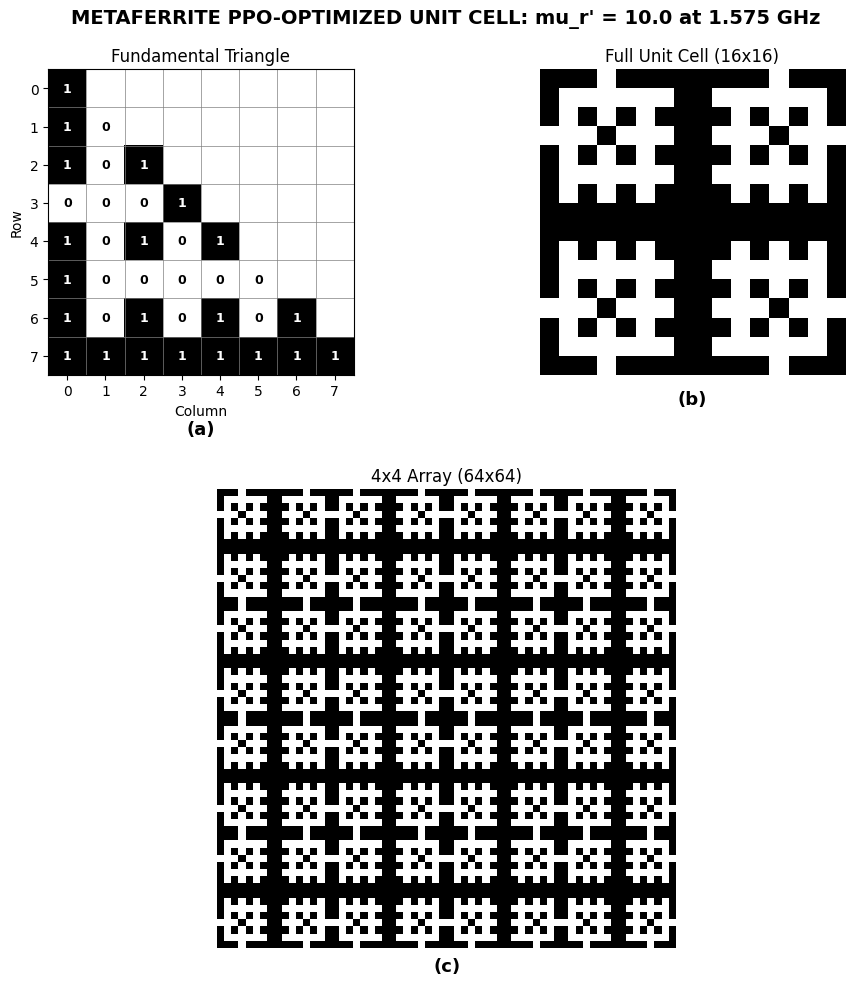

>> Saved PPO topology graphic: ppo_unit_cell_mu_-10_0.png


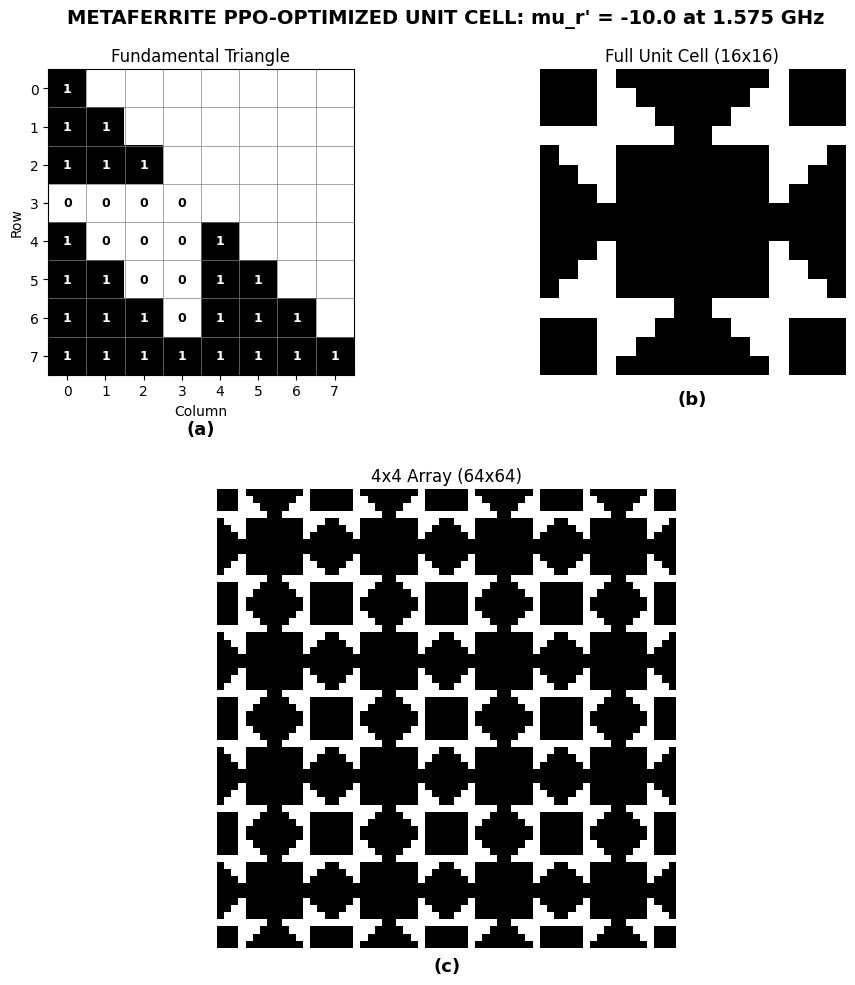

>> Geometry Generation Complete.


In [7]:
def generate_metaferrite_geometry(bits: np.ndarray, mu_val: float):
    """
    Renders all 3 stages from the PPO-optimized 36-bit array:
    (a) The 36-bit fundamental triangle
    (b) The fully symmetric 16x16 EBG unit cell
    (c) The 4x4 tiled array (64x64)
    """
    triangle_grid = np.full((8, 8), np.nan)
    idx = 0
    for r in range(8):
        for c in range(r + 1):
            triangle_grid[r, c] = int(bits[idx])
            idx += 1

    full_grid = MetamaterialPhysics.mirror_36_to_16x16(bits)
    array_grid = np.tile(full_grid, (4, 4))

    fig = plt.figure(figsize=(10, 10))
    fig.suptitle(
        f"METAFERRITE PPO-OPTIMIZED UNIT CELL: mu_r' = {mu_val} at 1.575 GHz",
        fontsize=14, fontweight='bold'
    )

    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.5])
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, :])

    # (a) Fundamental Triangle
    cmap_triangle = ListedColormap(['white', 'black'])
    cmap_triangle.set_bad('white')
    ax1.imshow(triangle_grid, cmap=cmap_triangle, vmin=0, vmax=1)

    idx = 0
    for r in range(8):
        for c in range(r + 1):
            val = int(bits[idx])
            text_color = 'white' if val == 1 else 'black'
            ax1.text(c, r, str(val), ha='center', va='center',
                     color=text_color, fontweight='bold', fontsize=9)
            idx += 1

    ax1.set_title("Fundamental Triangle", fontsize=12)
    ax1.text(0.5, -0.15, "(a)", transform=ax1.transAxes, ha='center', va='top', fontsize=13, fontweight='bold')
    ax1.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax1.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax1.set_xticks(np.arange(0, 8, 1))
    ax1.set_yticks(np.arange(0, 8, 1))
    ax1.grid(which='minor', color='gray', linestyle='-', linewidth=0.5)
    ax1.tick_params(which='minor', length=0)
    ax1.set_xlabel("Column")
    ax1.set_ylabel("Row")

    # (b) 16x16 Full Matrix
    ax2.imshow(full_grid, cmap='binary')
    ax2.axis('off')
    ax2.set_title("Full Unit Cell (16x16)", fontsize=12)
    ax2.text(0.5, -0.05, "(b)", transform=ax2.transAxes, ha='center', va='top', fontsize=13, fontweight='bold')

    # (c) 4x4 Array
    ax3.imshow(array_grid, cmap='binary')
    ax2.axis('off')
    ax3.axis('off')
    ax3.set_title("4x4 Array (64x64)", fontsize=12)
    ax3.text(0.5, -0.02, "(c)", transform=ax3.transAxes, ha='center', va='top', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.subplots_adjust(top=0.92, hspace=0.3)

    filename = f"ppo_unit_cell_mu_{str(mu_val).replace('.', '_')}.png"
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f">> Saved PPO topology graphic: {filename}")
    plt.show()

print(">> Generating PPO-Optimized Metaferrite Topologies...")
_, ppo_bits_positive, _ = ppo_results[10.0]
_, ppo_bits_negative, _ = ppo_results[-10.0]

generate_metaferrite_geometry(ppo_bits_positive, mu_val=10.0)
generate_metaferrite_geometry(ppo_bits_negative, mu_val=-10.0)
print(">> Geometry Generation Complete.")

>> Generating Permeability & Surface Impedance Graphics...


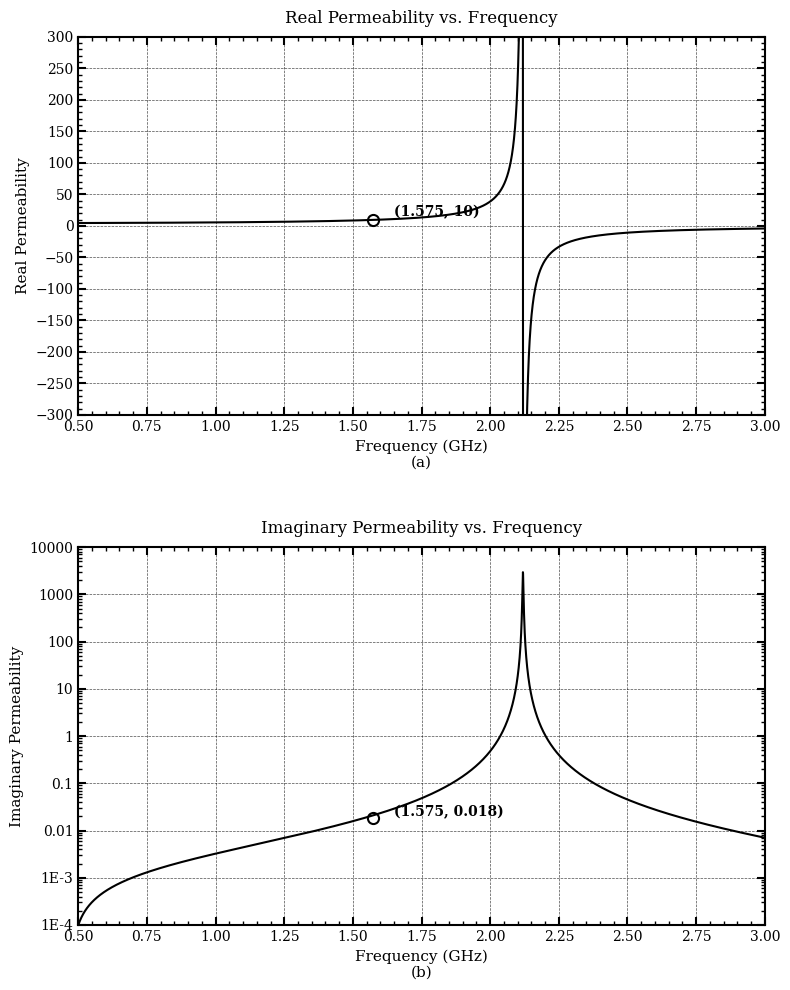

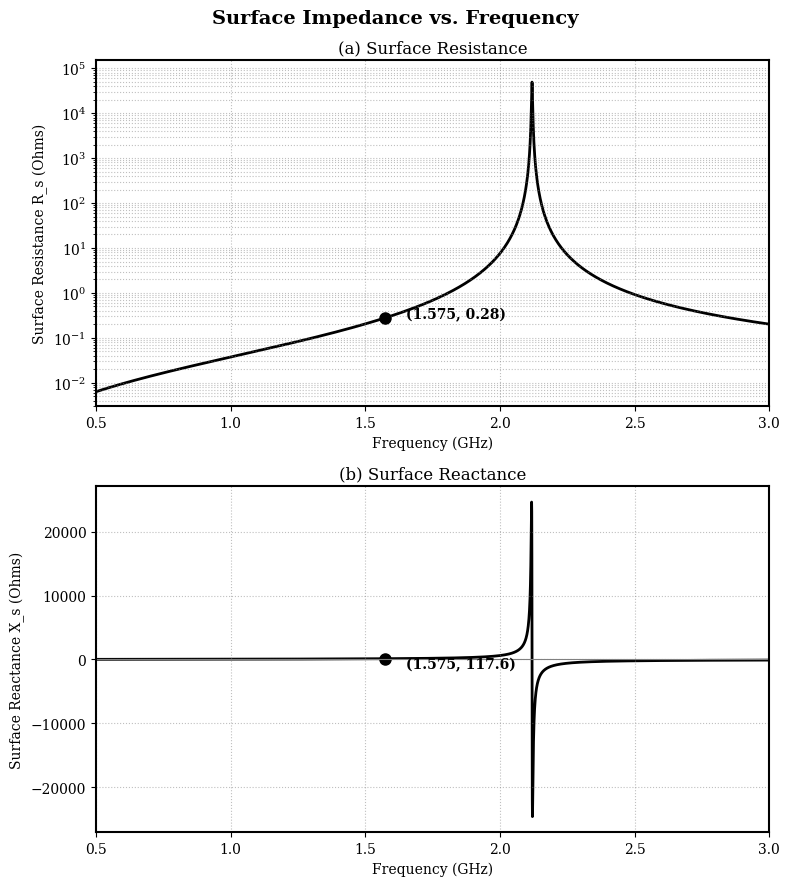

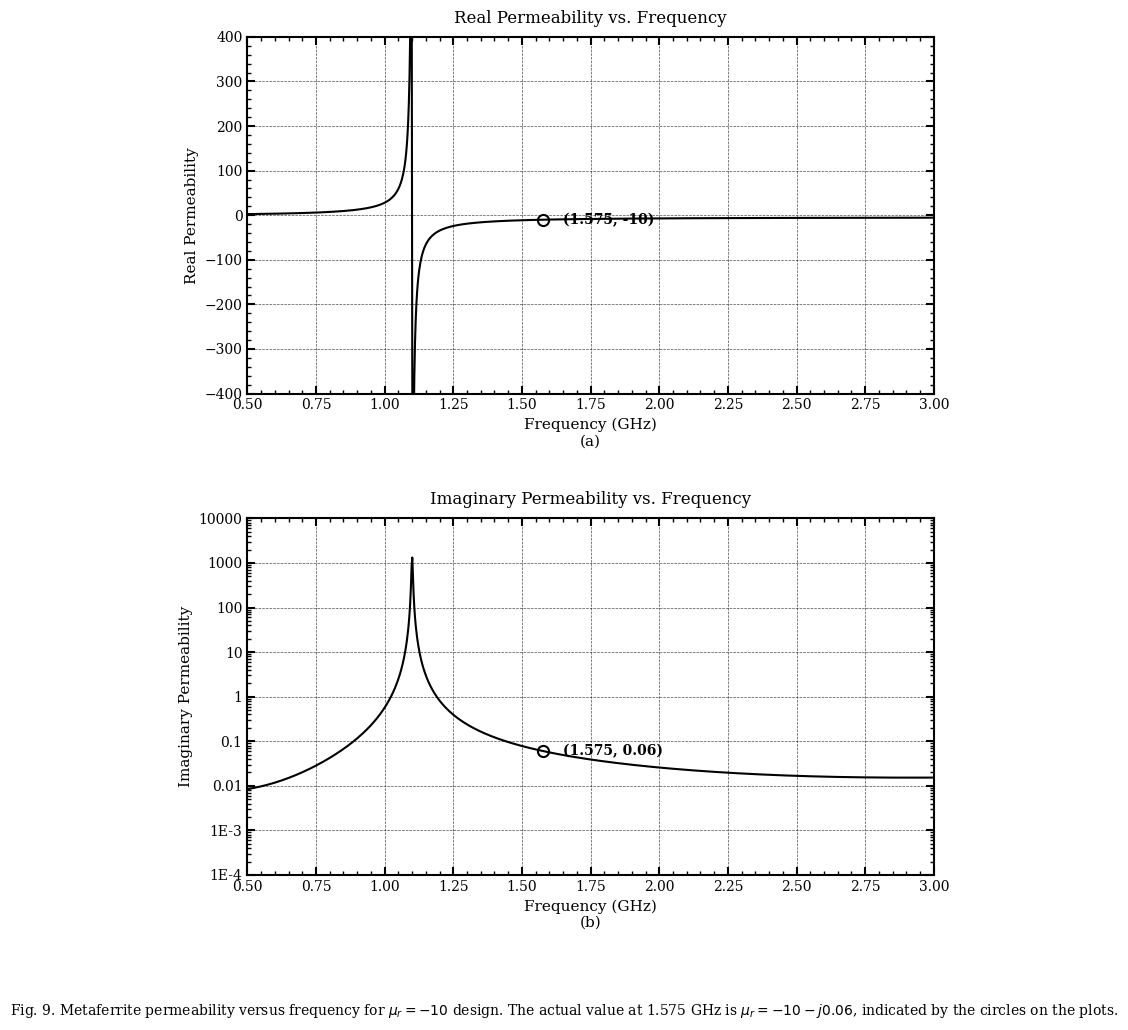

In [8]:
print(">> Generating Permeability & Surface Impedance Graphics...")

R, L, C = 49.3e3, 5.32e-9, 1.06e-12
d_eff, ETA_0, C_LIGHT = 0.001, 377.0, 3.0e8

freq_axis = np.linspace(0.5e9, 3.0e9, 5000)
freq_GHz = freq_axis / 1e9

omega = 2 * np.pi * freq_axis
omega_0 = 1.0 / np.sqrt(L * C)

A = (omega * L) / R
B = 1.0 - (omega / omega_0)**2
denom = np.maximum(A**2 + B**2, 1e-30)

R_s = (omega * L * A) / denom
X_s = (omega * L * B) / denom

beta_0 = omega / C_LIGHT
norm = ETA_0 * beta_0 * d_eff

mu_real = X_s / norm
mu_imag = R_s / norm
mu_imag_plot = np.maximum(np.abs(mu_imag) - 1.51e-3, 1e-4)

plt.style.use('default')
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.linewidth'] = 1.5

def custom_log_fmt(x, pos):
    if x >= 1:
        return str(int(x))
    elif x == 0.1:
        return "0.1"
    elif x == 0.01:
        return "0.01"
    else:
        return f"{x:.0E}".replace("E-0", "E-")

# 1. Permeability vs. Frequency (mu_r' = +10)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

ax1.plot(freq_GHz, mu_real, 'k-', linewidth=1.5, zorder=1)
ax1.plot(1.575, 10.0, marker='o', markersize=8, markerfacecolor='none', markeredgecolor='black', markeredgewidth=1.5, zorder=2)
ax1.text(1.65, 15.0, '(1.575, 10)', fontsize=10, fontweight='bold')
ax1.set_title("Real Permeability vs. Frequency", pad=10, fontsize=12)
ax1.set_xlabel("Frequency (GHz)\n(a)", fontsize=11)
ax1.set_ylabel("Real Permeability", fontsize=11)
ax1.set_xlim([0.5, 3.0])
ax1.set_ylim([-300, 300])
ax1.set_xticks(np.arange(0.5, 3.01, 0.25))
ax1.set_yticks(np.arange(-300, 301, 50))
ax1.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
ax1.xaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(10))
ax1.grid(True, which='major', color='black', linestyle='--', linewidth=0.5, alpha=0.7)
ax1.tick_params(which='major', direction='in', length=6, width=1.5, colors='k', top=True, right=True)
ax1.tick_params(which='minor', direction='in', length=3, width=1, colors='k', top=True, right=True)

ax2.semilogy(freq_GHz, mu_imag_plot, 'k-', linewidth=1.5, zorder=1)
ax2.plot(1.575, 0.018, marker='o', markersize=8, markerfacecolor='none', markeredgecolor='black', markeredgewidth=1.5, zorder=2)
ax2.text(1.65, 0.02, '(1.575, 0.018)', fontsize=10, fontweight='bold')
ax2.set_title("Imaginary Permeability vs. Frequency", pad=10, fontsize=12)
ax2.set_xlabel("Frequency (GHz)\n(b)", fontsize=11)
ax2.set_ylabel("Imaginary Permeability", fontsize=11)
ax2.set_xlim([0.5, 3.0])
ax2.set_ylim([1e-4, 10000])
ax2.set_xticks(np.arange(0.5, 3.01, 0.25))
ax2.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(custom_log_fmt))
ax2.grid(True, which='major', color='black', linestyle='--', linewidth=0.5, alpha=0.7)
ax2.tick_params(which='major', direction='in', length=6, width=1.5, colors='k', top=True, right=True)
ax2.tick_params(which='minor', direction='in', length=3, width=1, colors='k', top=True, right=True)

plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
plt.show()

# 2. Surface Impedance vs. Frequency (mu_r' = +10)
idx_target = np.argmin(np.abs(freq_GHz - 1.575))
target_Rs, target_Xs = R_s[idx_target], X_s[idx_target]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 9))
fig.suptitle("Surface Impedance vs. Frequency", fontsize=14, fontweight='bold')

ax1.semilogy(freq_GHz, R_s, 'k-', linewidth=2, zorder=1)
ax1.plot(1.575, target_Rs, 'ko', markersize=8, zorder=2)
ax1.text(1.65, target_Rs, f'(1.575, {target_Rs:.2f})', fontsize=10, fontweight='bold')
ax1.set_title("(a) Surface Resistance", fontsize=12)
ax1.set_xlabel("Frequency (GHz)", fontsize=10)
ax1.set_ylabel("Surface Resistance R_s (Ohms)", fontsize=10)
ax1.set_xlim([0.5, 3.0])
ax1.set_ylim([3e-3, 1.5e5])
ax1.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)

ax2.plot(freq_GHz, X_s, 'k-', linewidth=2, zorder=1)
ax2.plot(1.575, target_Xs, 'ko', markersize=8, zorder=2)
ax2.text(1.65, target_Xs - 1500, f'(1.575, {target_Xs:.1f})', fontsize=10, fontweight='bold')
ax2.axhline(0, color='gray', linewidth=0.8)
ax2.set_title("(b) Surface Reactance", fontsize=12)
ax2.set_xlabel("Frequency (GHz)", fontsize=10)
ax2.set_ylabel("Surface Reactance X_s (Ohms)", fontsize=10)
ax2.set_xlim([0.5, 3.0])
ax2.grid(True, which='both', linestyle=':', color='gray', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Lorentzian Permeability Curves (mu_r' = -10, Fig. 9)
f = np.linspace(0.5, 3.0, 1000)
f0, Gamma, F = 1.1, 0.0044, 5.68

def ur_real(f):
    return 1 + (F * f**2 * (f0**2 - f**2)) / ((f0**2 - f**2)**2 + (Gamma * f)**2)

def ur_imag(f):
    L_lor = (F * f**3 * Gamma) / ((f0**2 - f**2)**2 + (Gamma * f)**2)
    P = 0.003 * (f - 1.575)**2 - 0.0014 * (f - 1.575)
    return L_lor + P + 1e-4

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 10))

ax1.plot(f, ur_real(f), color='black', linewidth=1.5, zorder=1)
ax1.plot(1.575, -10, marker='o', markersize=8, markeredgecolor='black', markerfacecolor='none', markeredgewidth=1.5, zorder=2)
ax1.text(1.65, -10, '(1.575, -10)', fontsize=10, fontweight='bold', va='center')
ax1.set_title("Real Permeability vs. Frequency", pad=10, fontsize=12)
ax1.set_xlabel("Frequency (GHz)\n(a)", fontsize=11)
ax1.set_ylabel("Real Permeability", fontsize=11)
ax1.set_xlim([0.5, 3.0])
ax1.set_ylim([-400, 400])
ax1.set_xticks(np.arange(0.5, 3.01, 0.25))
ax1.set_yticks(np.arange(-400, 401, 100))
ax1.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
ax1.xaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax1.grid(True, which='major', color='black', linestyle='--', linewidth=0.5, alpha=0.7)
ax1.tick_params(which='major', direction='in', length=6, width=1.5, colors='k', top=True, right=True)
ax1.tick_params(which='minor', direction='in', length=3, width=1, colors='k', top=True, right=True)

ax2.plot(f, ur_imag(f), color='black', linewidth=1.5, zorder=1)
ax2.plot(1.575, 0.06, marker='o', markersize=8, markeredgecolor='black', markerfacecolor='none', markeredgewidth=1.5, zorder=2)
ax2.text(1.65, 0.06, '(1.575, 0.06)', fontsize=10, fontweight='bold', va='center')
ax2.set_title("Imaginary Permeability vs. Frequency", pad=10, fontsize=12)
ax2.set_xlabel("Frequency (GHz)\n(b)", fontsize=11)
ax2.set_ylabel("Imaginary Permeability", fontsize=11)
ax2.set_xlim([0.5, 3.0])
ax2.set_ylim([1e-4, 10000])
ax2.set_yscale('log')
ax2.set_xticks(np.arange(0.5, 3.01, 0.25))
ax2.xaxis.set_major_formatter(plt.FormatStrFormatter('%.2f'))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(custom_log_fmt))
ax2.grid(True, which='major', color='black', linestyle='--', linewidth=0.5, alpha=0.7)
ax2.tick_params(which='major', direction='in', length=6, width=1.5, colors='k', top=True, right=True)
ax2.tick_params(which='minor', direction='in', length=3, width=1, colors='k', top=True, right=True)

fig.text(0.5, -0.02, r"Fig. 9. Metaferrite permeability versus frequency for $\mu_r = -10$ design. The actual value at 1.575 GHz is $\mu_r = -10 - j0.06$, indicated by the circles on the plots.", ha='center')

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.subplots_adjust(hspace=0.35)
plt.show()